# 🕵️ Détection de fraude bancaire avec Python

**Objectif** : créer un modèle qui reconnaît si une transaction bancaire est **normale (0)** ou **frauduleuse (1)**.

**Les grandes étapes :**
1. Charger et explorer les données
2. Comprendre le problème du déséquilibre (très peu de fraudes)
3. Séparer les données en une partie *entraînement* et une partie *test*
4. Entraîner un premier modèle simple
5. Corriger le déséquilibre et comparer
6. Évaluer avec les bons indicateurs (matrice de confusion, précision, rappel, F1-score)

## 1. Importer les bibliothèques
Ce sont les « outils » dont on a besoin.

In [39]:
import pandas as pd                # manipuler les tableaux de données
import numpy as np                 # calculs
import matplotlib.pyplot as plt    # faire des graphiques

from sklearn.model_selection import train_test_split          # séparer entraînement / test
from sklearn.preprocessing import StandardScaler              # mettre les valeurs à la même échelle
from sklearn.linear_model import LogisticRegression           # notre 1er modèle
from sklearn.ensemble import RandomForestClassifier           # notre 2e modèle
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_score,
                             recall_score, f1_score)

In [40]:
import os
print(os.listdir("."))

['.config', 'creditcard.csv', 'sample_data']


## 2. Charger les données


In [41]:
df = pd.read_csv("creditcard.csv")
df.head()   # affiche les 5 premières lignes

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Explorer les données (EDA)
On regarde à quoi ressemble le tableau avant de faire quoi que ce soit.

In [42]:
print("Nombre de lignes et de colonnes :", df.shape)
print()
df.info()

Nombre de lignes et de colonnes : (284807, 31)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  

In [43]:
# Y a-t-il des valeurs manquantes ?
print("Valeurs manquantes au total :", df.isnull().sum().sum())

Valeurs manquantes au total : 0


In [44]:
# Statistiques simples sur le montant et le temps
df[["Time", "Amount"]].describe()

,Time,Amount
count,284807.000000,284807.000000
mean,94813.859575,88.349619
std,47488.145955,250.120109
min,0.000000,0.000000
25%,54201.500000,5.600000
50%,84692.000000,22.000000
75%,139320.500000,77.165000
max,172792.000000,25691.160000


**Ce qu'il faut savoir sur les colonnes :**
- `Time` : secondes écoulées depuis la première transaction
- `Amount` : montant de la transaction
- `V1` à `V28` : informations **anonymisées** (pour protéger les clients)
- `Class` : **0 = normale, 1 = fraude** → c'est ce qu'on veut prédire

## 4. Le problème du déséquilibre des classes

In [45]:
compte = df["Class"].value_counts()
print(compte)
print()
print("Pourcentage de fraudes :", round(df["Class"].mean() * 100, 3), "%")

Class
0    284315
1       492
Name: count, dtype: int64

Pourcentage de fraudes : 0.173 %


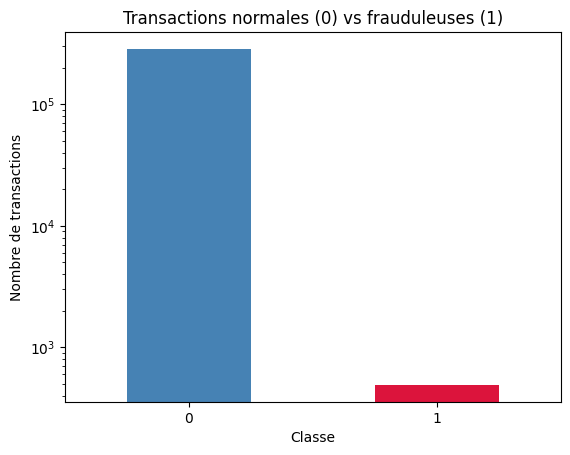

In [46]:
compte.plot(kind="bar", color=["steelblue", "crimson"])
plt.title("Transactions normales (0) vs frauduleuses (1)")
plt.xlabel("Classe")
plt.ylabel("Nombre de transactions")
plt.xticks(rotation=0)
plt.yscale("log")   # échelle logarithmique, sinon on ne verrait pas les fraudes
plt.show()

👉 **Constat** : les fraudes représentent environ **0,17 %** des transactions. Les données sont donc très **déséquilibrées**.

**Pourquoi c'est un problème ?** Un modèle qui répondrait toujours « pas de fraude » aurait 99,8 % de bonnes réponses… tout en étant totalement inutile ! Vérifions :

In [47]:
accuracy_betement_normal = (df["Class"] == 0).mean()
print("Accuracy d'un modèle qui dit toujours 'normal' :", round(accuracy_betement_normal * 100, 2), "%")

Accuracy d'un modèle qui dit toujours 'normal' : 99.83 %


C'est pour cela qu'on n'utilisera **pas** l'accuracy (le % de bonnes réponses), mais :
- **Précision** : quand le modèle dit « fraude », a-t-il raison ?
- **Rappel (recall)** : parmi toutes les vraies fraudes, combien en a-t-on trouvé ?
- **F1-score** : un compromis entre précision et rappel

## 5. Préparer les données

### 5.1 Mettre `Amount` et `Time` à la même échelle
`Amount` peut aller jusqu'à plusieurs milliers alors que les colonnes V1 à V28 sont petites. On les met à la même échelle pour aider le modèle.

In [48]:
# Séparer les variables (X) et la cible à prédire (y)
X = df.drop("Class", axis=1)
y = df["Class"]

### 5.2 Séparer en données d'entraînement et de test
- **Entraînement (80 %)** : le modèle apprend dessus
- **Test (20 %)** : on le garde de côté pour vérifier le modèle sur des données qu'il n'a **jamais vues**

`stratify=y` garantit qu'on retrouve la même proportion de fraudes dans les deux parties.

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,   # pour obtenir toujours le même résultat
    stratify=y
)

print("Taille entraînement :", X_train.shape[0])
print("Taille test         :", X_test.shape[0])
print("Fraudes dans l'entraînement :", y_train.sum())
print("Fraudes dans le test        :", y_test.sum())

Taille entraînement : 227845
Taille test         : 56962
Fraudes dans l'entraînement : 394
Fraudes dans le test        : 98


In [50]:
# On met Amount et Time à l'échelle.
# IMPORTANT : on "apprend" l'échelle sur l'entraînement seulement (fit),
# puis on l'applique au test (transform), pour ne pas tricher.
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[["Time", "Amount"]] = scaler.fit_transform(X_train[["Time", "Amount"]])
X_test[["Time", "Amount"]] = scaler.transform(X_test[["Time", "Amount"]])

## 6. Fonction pour évaluer un modèle
On écrit une fonction une seule fois, et on la réutilise pour chaque modèle.

In [51]:
resultats = {}   # on y stockera les scores de chaque modèle

def evaluer(nom, modele):
    # Le modèle fait ses prédictions sur le jeu de TEST
    y_pred = modele.predict(X_test)

    # Les 3 indicateurs (calculés pour la classe 1 = fraude)
    precision = precision_score(y_test, y_pred)
    rappel = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    resultats[nom] = {"Précision": precision, "Rappel": rappel, "F1-score": f1}

    print("=== ", nom, " ===")
    print("Précision :", round(precision, 3))
    print("Rappel    :", round(rappel, 3))
    print("F1-score  :", round(f1, 3))

    # Matrice de confusion
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Normale", "Fraude"]).plot(cmap="Blues")
    plt.title("Matrice de confusion - " + nom)
    plt.show()

## 7. Modèle 1 : Régression logistique (sans corriger le déséquilibre)
C'est le modèle le plus simple pour de la classification : il calcule la probabilité qu'une transaction soit une fraude.

===  Régression logistique (simple)  ===
Précision : 0.829
Rappel    : 0.643
F1-score  : 0.724


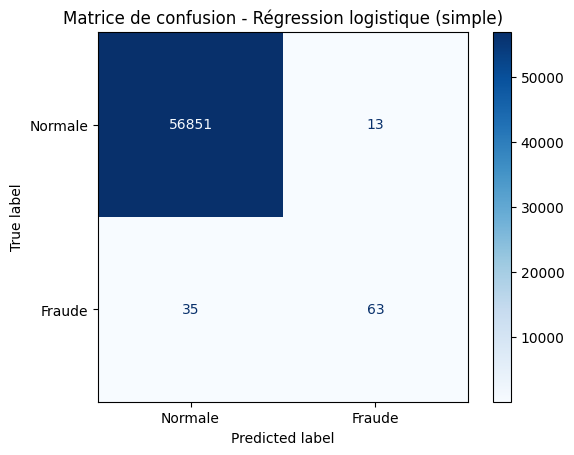

In [52]:
modele1 = LogisticRegression(max_iter=1000)
modele1.fit(X_train, y_train)     # le modèle apprend
evaluer("Régression logistique (simple)", modele1)


- En haut à gauche : transactions normales bien reconnues ✅
- En bas à droite : fraudes bien détectées ✅
- En haut à droite : fausses alertes (normale classée « fraude »)
- **En bas à gauche : fraudes ratées** ❌ (le plus grave pour une banque)

## 8. Modèle 2 : Régression logistique avec gestion du déséquilibre
On utilise `class_weight="balanced"` : le modèle donne **plus d'importance** aux rares fraudes pendant l'apprentissage. C'est simple et efficace.

===  Régression logistique (équilibrée)  ===
Précision : 0.061
Rappel    : 0.918
F1-score  : 0.114


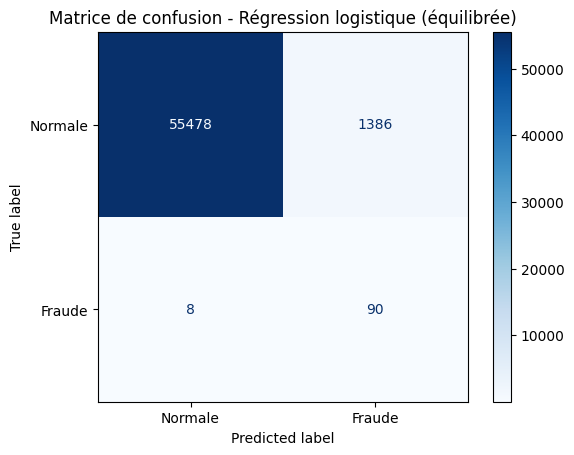

In [53]:
modele2 = LogisticRegression(max_iter=1000, class_weight="balanced")
modele2.fit(X_train, y_train)
evaluer("Régression logistique (équilibrée)", modele2)

👉 Normalement, le **rappel augmente** (on rate moins de fraudes), mais la **précision baisse** (plus de fausses alertes). C'est un compromis classique.

## 9. Modèle 3 : Random Forest (forêt aléatoire)
Ce modèle construit de nombreux « arbres de décision » et fait voter l'ensemble. Il est souvent plus performant. ⏱️ L'entraînement peut prendre 1 à 3 minutes.

===  Random Forest (équilibré)  ===
Précision : 0.96
Rappel    : 0.735
F1-score  : 0.832


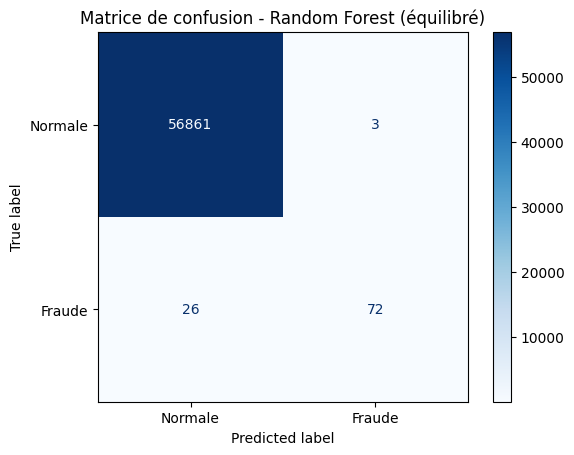

In [54]:
modele3 = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",   # gestion du déséquilibre
    random_state=42,
    n_jobs=-1
)
modele3.fit(X_train, y_train)
evaluer("Random Forest (équilibré)", modele3)

## 10. Comparer les trois modèles

In [55]:
tableau = pd.DataFrame(resultats).T.round(3)
tableau

,Précision,Rappel,F1-score
Régression logistique (simple),0.829,0.643,0.724
Régression logistique (équilibrée),0.061,0.918,0.114
Random Forest (équilibré),0.960,0.735,0.832


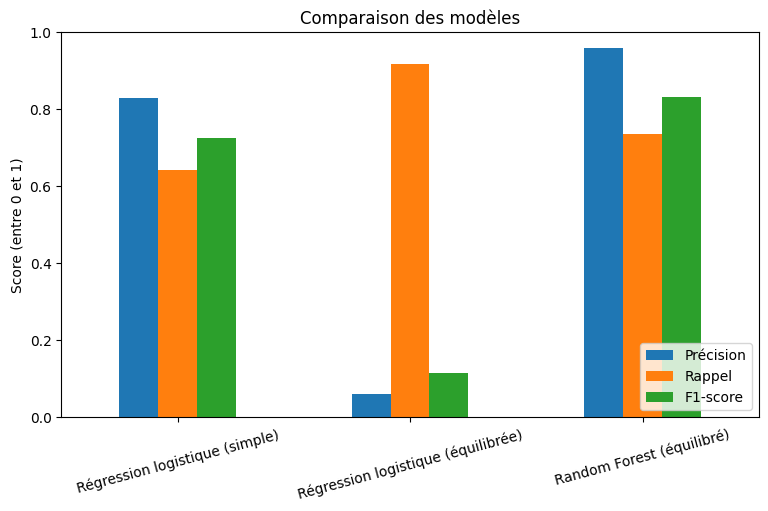

In [56]:
tableau.plot(kind="bar", figsize=(9, 5))
plt.title("Comparaison des modèles")
plt.ylabel("Score (entre 0 et 1)")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()

## 11. Rapport détaillé du meilleur modèle

In [57]:
# Remplace modele3 par le modèle qui a le meilleur F1-score dans ton tableau
print(classification_report(y_test, modele3.predict(X_test), target_names=["Normale", "Fraude"]))

              precision    recall  f1-score   support

     Normale       1.00      1.00      1.00     56864
      Fraude       0.96      0.73      0.83        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962



## 12. Conclusion

- Le jeu de données contient 284 807 transactions dont seulement ~0,17 % de fraudes.
- L'accuracy n'est pas adaptée à ce type de problème : on utilise précision, rappel et F1-score.
- La gestion du déséquilibre (`class_weight`) permet de mieux détecter les fraudes.
- Le meilleur modèle est **............** avec un F1-score de **....** (précision **....**, rappel **....**).

